# FINAL PROJECT - GROUP 15 - EDA

## 1. Tổng quan về dữ liệu

### 1.1 Nguồn dữ liệu
- Bộ dữ liệu AI Developer Perfomance được lấy từ **Kaggle:** [AI Dev Performance](https://www.kaggle.com/datasets/brandmustafa/ai-dev-performance), tác giả chính của dataset này là **zeesolver**, và họ cũng đã cho phép phân tích cho mục đích học tập trong phần mô tả. Tuy nhiên, hiện tại bộ dataset này đã bị tác giả chỉnh thành private. Do đó, thông tin sơ bộ về dữ liệu của tác giả nhóm xin phép để trong file About.md trong folder dataset/raw/ (Đây là thông tin mà nhóm đã download về dataset trước khi bị tác giả chỉnh thành private dataset, như đã trao đổi với thầy Nam)


### 1.2 Mô tả nguồn dữ liệu

####  Giới thiệu
- Bộ dữ liệu này cung cấp góc nhìn sâu về phát triển phần mềm hỗ trợ bởi AI, tập trung vào các đặc trưng như **thời gian lập trình, mức độ sử dụng AI, mức độ stress, thời gian ngủ, áp lực lượng công việc, bugs, errors và commits** ảnh hưởng đến năng suất tổng thể của developer.
- Bộ dữ liệu này có thể giúp các nhà nghiên cứu, các chuyên gia ML và các nhà quản lý kỹ thuật phân tích cách hành vi của con người và các công cụ AI định hình kết quả lập trình.

#### Tổng quan về bộ dữ liệu
- **1000 dòng** - dữ liệu sạch và đầy đủ
- **13 đặc trưng** mô tả hiệu suất của developer có sử dụng AI để hỗ trợ.

Các đặc trưng được chia thành các nhóm như sau:

| Category | Features |
|----------|----------|
| **Productivity** | Hours_Coding, Lines_of_Code, Commits, Task_Duration_Hours |
| **Quality & Errors** | Bugs_Found, Bugs_Fixed, Errors |
| **AI Usage** | AI_Usage_Hours |
| **Human Condition** | Sleep_Hours, Coffee_Intake, Stress_Level, Cognitive_Load |
| **Performance Outcome** | Task_Success_Rate |

### 1.3 Phương pháp thu thập dữ liệu
- Theo tác giả của bộ dữ liệu, các dữ liệu này được thu thập bằng cách tổng hợp các khảo sát ở nhiều nguồn khác nhau trên Internet.
- Hạn chế tiềm ẩn: Vì thiếu cơ chế kiểm soát người trả lời thực tế, dữ liệu dễ bị nhiễu, thiếu trung thực, làm giảm độ tin cậy của kết quả.

### 1.4 Lý do lựa chọn
- Năm 2025, AI đã trở thành một phần thiết yếu của kỹ thuật phần mềm hiện đại, và việc hiểu hiệu suất của con người và AI giờ đây quan trọng hơn bao giờ hết.
- Bộ dữ liệu phù hợp với mục tiêu nghiên cứu của nhóm, gồm nhiều đặc trưng có thể đưa ra các phân tích, trực quan hóa và áp dụng mô hình học máy.

### 1.5 Hạn chế của dữ liệu
- Vì nguồn chỉ nói rằng "thu thập từ nhiều nguồn tổng hợp khác nhau trên mạng" nên chất lượng của dữ liệu không hoàn toàn được chắc chắn (Mặc dù đạt được **gold medal** trên Kaggle).
- Số dòng chỉ có 1000, khá ít so với những bộ dữ liệu khác.

## 2. Khám phá dữ liệu

Khai báo các thư viện cần thiết

In [1]:
import warnings
warnings.filterwarnings("ignore")

import sys
sys.path.append("..")

import pandas as pd
from src import config
from src.preprocess import DataProcessor
from src.eda import OutlierAnalyzer, CorrelationAnalyzer
from src.visualize import Plotter

### 2.1 Các thông số cơ bản của dữ liệu

Trong phần này, chúng ta sẽ tìm hiểu những thông số cơ bản của dataset như sau:
- Số dòng, số cột
- Số dòng dữ liệu bị thiếu, bị trùng
- Kiểu dữ liệu của các cột
- Các thông số thống kê: min, max, mean, std, tứ phân vị

Load dữ liệu và đọc số dòng, số cột

In [2]:
df = DataProcessor.load_data(config.RAW_DATA_DIR)

Kích thước: 1000 dòng, 13 cột


Kiểm tra 5 dòng đầu tiên và tên từng cột, số dòng null, kiểu dữ liêu

In [3]:
df.head()

,Hours_Coding,Lines_of_Code,Bugs_Found,Bugs_Fixed,AI_Usage_Hours,Sleep_Hours,Cognitive_Load,Task_Success_Rate,Coffee_Intake,Stress_Level,Task_Duration_Hours,Commits,Errors
0,7,416,9,7,6,5.9,92,34,7,99,10.5,20,3
1,4,269,16,13,5,5.1,85,36,2,100,9.5,17,8
2,11,439,3,0,2,6.2,38,79,2,55,18.3,35,2
3,8,472,15,9,4,4.2,26,94,5,30,12.6,28,4
4,5,265,19,16,5,8.1,82,33,6,82,7.0,25,9


Kiểm tra tên từng cột, số dòng null, kiểu dữ liệu

In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 13 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   Hours_Coding         1000 non-null   int64  
 1   Lines_of_Code        1000 non-null   int64  
 2   Bugs_Found           1000 non-null   int64  
 3   Bugs_Fixed           1000 non-null   int64  
 4   AI_Usage_Hours       1000 non-null   int64  
 5   Sleep_Hours          1000 non-null   float64
 6   Cognitive_Load       1000 non-null   int64  
 7   Task_Success_Rate    1000 non-null   int64  
 8   Coffee_Intake        1000 non-null   int64  
 9   Stress_Level         1000 non-null   int64  
 10  Task_Duration_Hours  1000 non-null   float64
 11  Commits              1000 non-null   int64  
 12  Errors               1000 non-null   int64  
dtypes: float64(2), int64(11)
memory usage: 101.7 KB


Vậy là dữ liệu không có cột nào bị thiếu dữ liệu.

Ngoài ra, kiểu dữ liệu của tất cả các cột đều là số thực (float) hoặc số nguyên (int), không cần phải chuyển đổi kiểu dữ liệu.

Tiếp theo là kiểm tra xem có dòng nào bị lặp lại (duplicate) không?

In [5]:
print(f"Số dòng bị lặp: {df.duplicated().sum()}")

Số dòng bị lặp: 0


Vậy không có dòng nào bị lặp lại. Tiếp tục kiểm tra các thông số thống kê của dữ liệu (mean, std, ...)

In [6]:
df.describe()

,Hours_Coding,Lines_of_Code,Bugs_Found,Bugs_Fixed,AI_Usage_Hours,Sleep_Hours,Cognitive_Load,Task_Success_Rate,Coffee_Intake,Stress_Level,Task_Duration_Hours,Commits,Errors
count,1000.00000,1000.00000,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000
mean,5.84000,356.23400,9.876000,7.153000,2.961000,6.465800,56.933000,56.578000,3.368000,66.410000,8.700100,17.253000,4.544000
std,3.15854,188.15535,5.796052,5.468226,2.021278,1.439529,21.767506,20.814879,2.342234,21.865452,5.992891,10.836901,2.820997
min,1.00000,26.00000,0.000000,0.000000,0.000000,4.000000,20.000000,30.000000,0.000000,30.000000,0.500000,1.000000,0.000000
25%,3.00000,209.50000,5.000000,2.000000,1.000000,5.200000,38.000000,37.000000,1.000000,48.000000,4.000000,9.000000,2.000000
50%,6.00000,332.00000,10.000000,7.000000,3.000000,6.400000,57.000000,55.500000,3.000000,66.000000,7.450000,14.000000,5.000000
75%,9.00000,480.50000,15.000000,12.000000,5.000000,7.700000,76.000000,74.000000,5.000000,86.000000,12.000000,23.000000,7.000000
max,11.00000,993.00000,19.000000,19.000000,6.000000,9.000000,94.000000,100.000000,7.000000,100.000000,27.500000,50.000000,9.000000


### 2.2 Tìm hiểu các cột dữ liệu

Ý nghĩa của mỗi cột dữ liệu:

| Tên Cột | Mô tả |
| :--- | :--- |
| **Hours_Coding** | Số giờ dành cho việc lập trình mỗi ngày. |
| **Lines_of_Code** | Tổng số dòng code đã viết. |
| **Bugs_Found** | Số lượng lỗi (bugs) được phát hiện. |
| **Bugs_Fixed** | Số lượng lỗi (bugs) đã được sửa chữa. |
| **AI_Usage_Hours** | Số giờ sử dụng các công cụ hỗ trợ lập trình bằng AI. |
| **Sleep_Hours** | Số giờ ngủ trung bình mỗi ngày. |
| **Cognitive_Load** | Điểm số áp lực nhận thức/tinh thần (thang 0–100). |
| **Task_Success_Rate** | Tỷ lệ thành công/hoàn thành tác vụ (thang 0–100). |
| **Coffee_Intake** | Số lượng tách cà phê tiêu thụ mỗi ngày. |
| **Stress_Level** | Mức độ căng thẳng (thang 0–100). |
| **Task_Duration_Hours** | Thời gian (tính bằng giờ) để hoàn thành một tác vụ. |
| **Commits** | Tổng số lần commit trên Git. |
| **Errors** | Số lượng lỗi kỹ thuật (errors) trong quá trình code. |

Trong dữ liệu hiện tại, có 2 cột sau: `AI_Usage_Hours`, `Hours_Coding`. Liệu thời gian sử dụng AI có tính vào thời gian Code hay không?

Ngoài ra, có 2 cột rất liên quan tới nhau: `Bug_Fixed` và `Bugs_Found`. Liệu dữ liệu có sạch không? Tức là số lượng bug được tìm thấy >= số lượng bug đã được fix.

Cuối cùng, tổng thời gian làm việc có hợp lí hay không (Thời gian làm việc + Thời gian ngủ <= 24 tiếng)?

Để tìm hiểu những điều trên, chúng em sẽ cài đặt một đoạn code để kiểm tra.

In [7]:
# AI Usage > Hours Coding?
condition = df['AI_Usage_Hours'] > df['Hours_Coding']
DataProcessor._check_condition(df, condition, "AI Usage Hours > Hours Coding")

# Bugs Fixed > Bugs Found?
condition = df['Bugs_Fixed'] > df['Bugs_Found']
DataProcessor._check_condition(df, condition, "Bugs Fixed > Bugs Found");

AI Usage Hours > Hours Coding: 201
Bugs Fixed > Bugs Found: 0


Do đó, số giờ code và số giờ sử dụng AI là 2 việc hoàn toàn khác nhau

In [8]:
# Total Hours = Coding + AI + Sleep >= 24h?
total_hours = df['Hours_Coding'] + df['AI_Usage_Hours'] + df['Sleep_Hours']
condition = total_hours >= 24
DataProcessor._check_condition(df, condition, "Total Hours >= 24h", show_pct=True)

# Thống kê dữ liệu cột Total Hours
total_hours.describe()

Total Hours >= 24h: 11 (1.10%)


count    1000.000000
mean       15.266800
std         3.996364
min         5.400000
25%        12.400000
50%        15.250000
75%        18.100000
max        25.600000
dtype: float64

Dựa trên kết quả trên, chúng em rút ra được kết luận:
- Số giờ xài AI và số giờ code là 2 việc hoàn toàn khác nhau.
- Các cột liên quan tới bug hoàn toàn hợp lí
- Thời gian làm việc và ngủ của mỗi người trong dataset sẽ có mean là 15 tiếng, min là 5.4 tiếng và max là 25.6 tiếng. Điều này có nghĩa là mặc dù đa số đều ở mức bình thường, vẫn có 1 số outliers với những thông số rất kì lạ. Ví dụ một người có thời gian trên lên tới 25.6 tiếng (Vô lí). Nhưng chúng chỉ chiếm một lượng rất nhỏ với tỉ lệ 1,1% trên toàn bộ dataset, nên chúng em quyết định drop các dòng dữ liệu vô lí này.

In [9]:
initial_rows = len(df)
total_hours = df['Hours_Coding'] + df['AI_Usage_Hours'] + df['Sleep_Hours']
df = df[total_hours < 24].copy() # Clean data

dropped = initial_rows - len(df)
print(f"Gốc: {initial_rows} dòng")
print(f"Đã xóa: {dropped} dòng")
print(f"Còn lại: {len(df)} dòng")

Gốc: 1000 dòng
Đã xóa: 11 dòng
Còn lại: 989 dòng


### 2.3 Phân tích phân phối dữ liệu

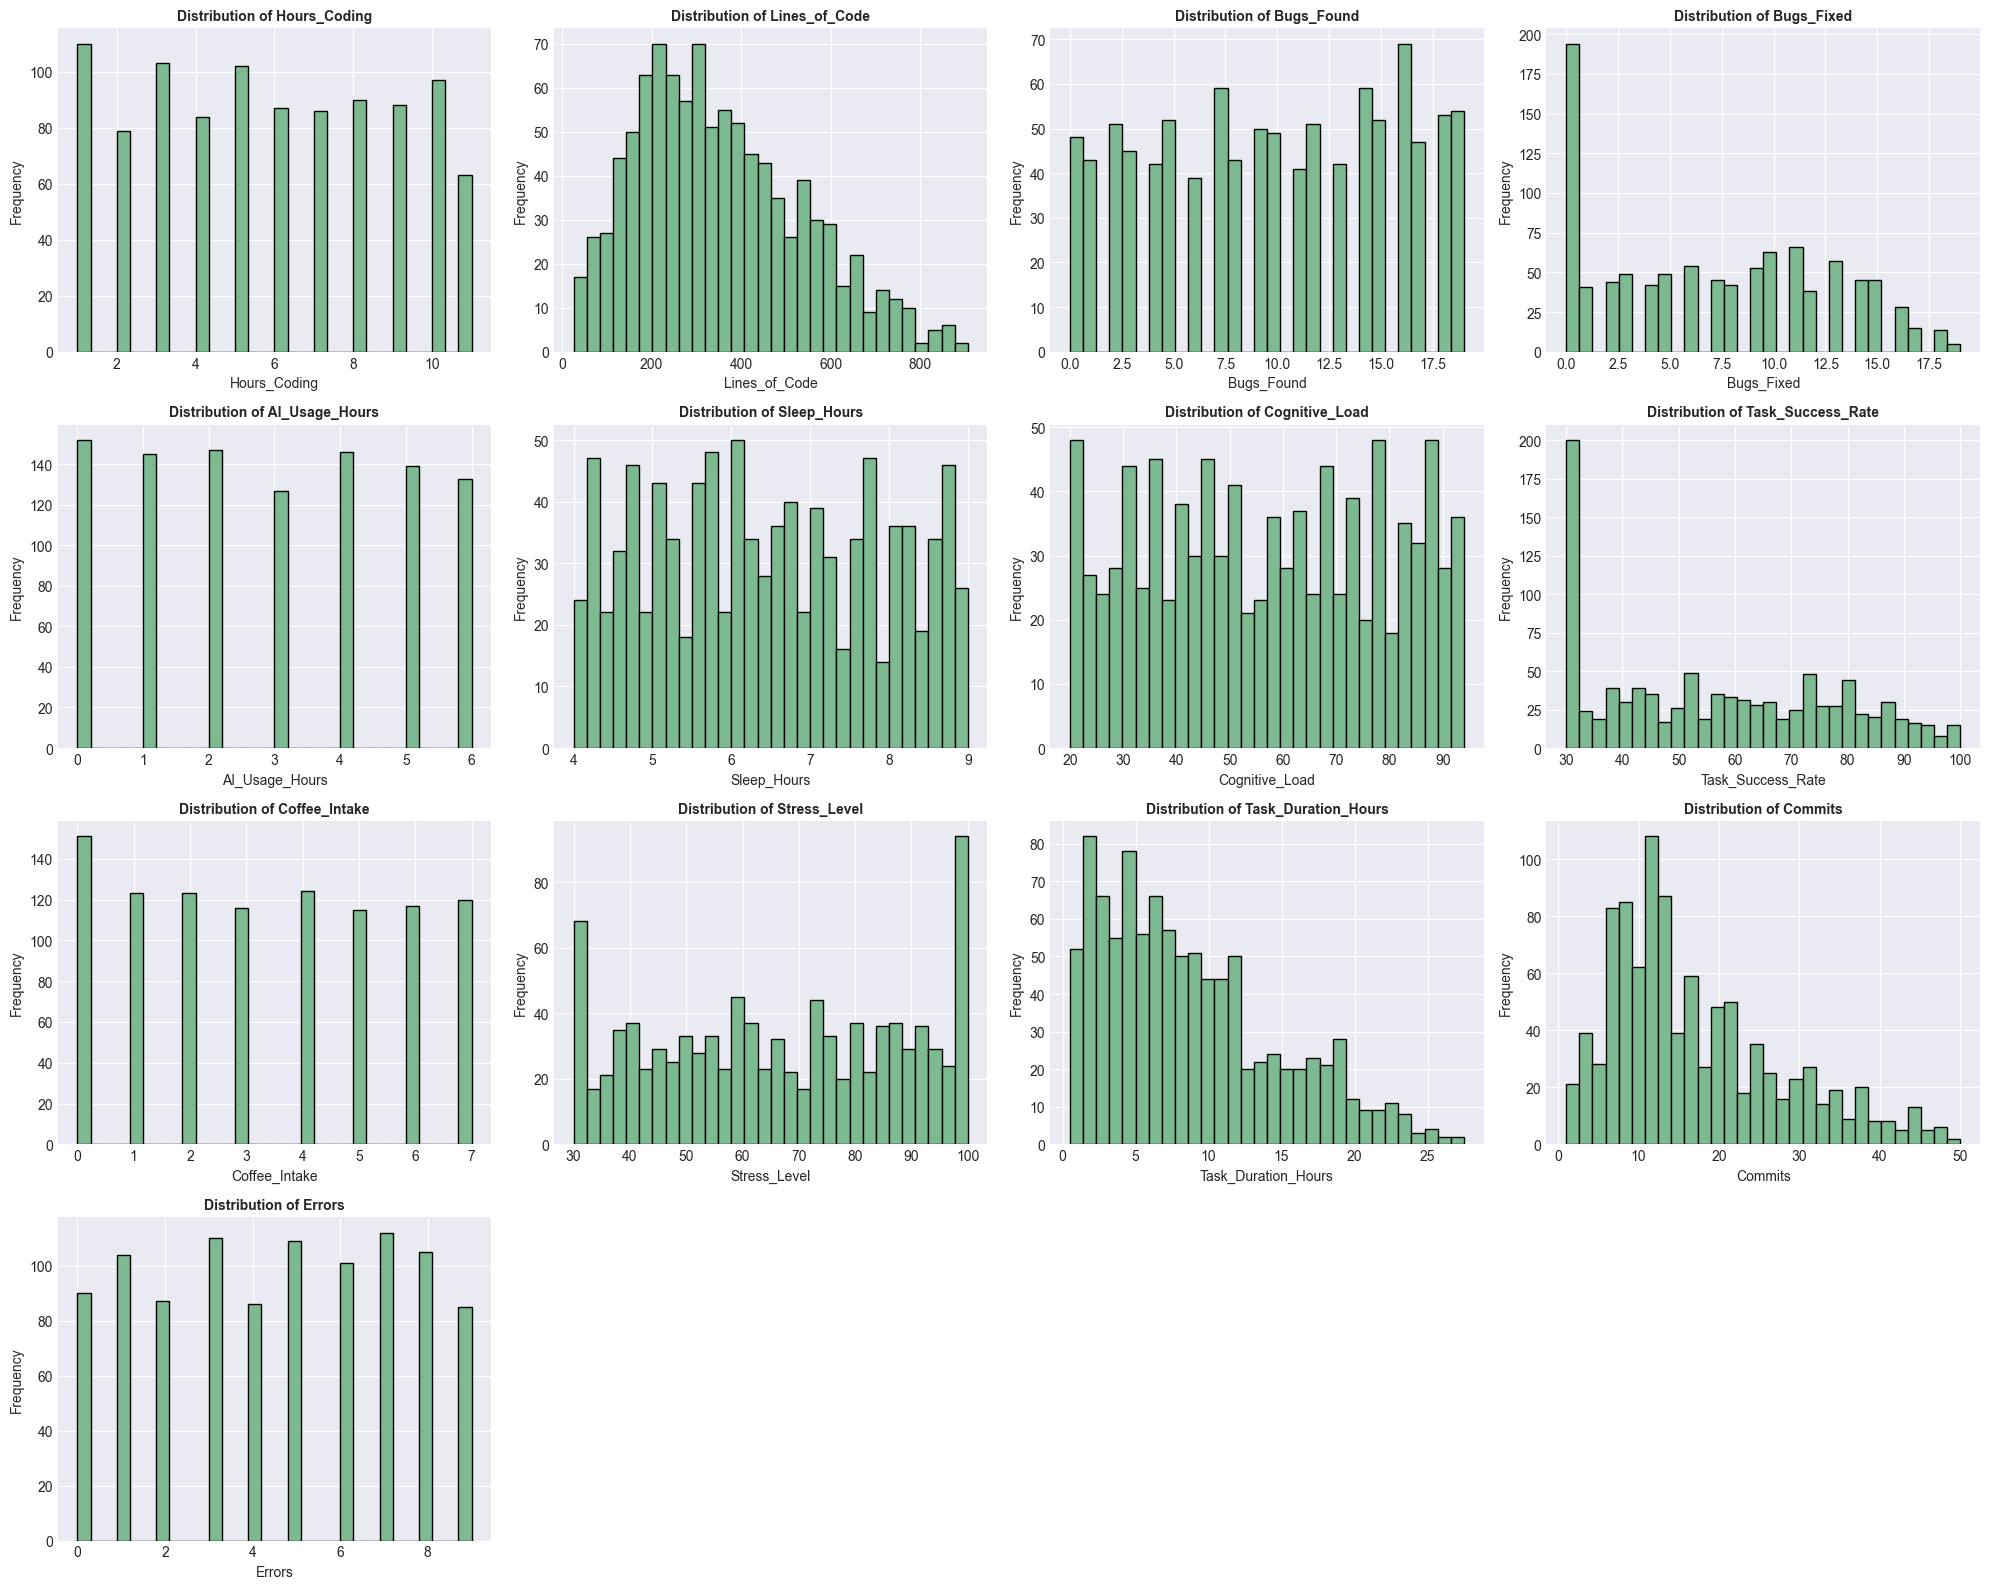

In [10]:
Plotter.histograms(df, n_cols=4, figsize=(20, 16))

Quan sát:
- Có một điều khá lạ ở `Sleep_Hours` là dữ liệu không hề tuân theo phân phối chuẩn.
- Ở `Task_Success_Rate`, mode nằm ở 30% (Và rất lớn so với những giá trị khác). Ở `Stress_Level`, mode lại nằm ở 100%.
- Ở `Lines_of_Code, Commits, Task_Duration_Hours`, các phân phối đều là right-skewed distribution. Điều này khá hợp lí trong thực tế vì đa số các task đều sẽ nằm ở mức đơn giản, chỉ có số ít là phức tạp.
- Ở `Errors, Coffee_Intake, AI_Usage_Hours, Hours_Coding`, dữ liệu đa số đều tuân theo phân phối chuẩn, điều này cũng khá kì lạ vì không có sự chênh lệch đáng kể.
- Ở `Bugs_Fixed, Bugs_Found`, mặc dù số lượng bug được tìm thấy tuân theo phân phối đều, nhưng lượng bug đã được fix lại có mode nằm ở giá trị 0.

Kiểm tra outliers bằng box plot

Số cột có outlier: 3
Các cột có outlier: ['Lines_of_Code', 'Task_Duration_Hours', 'Commits']


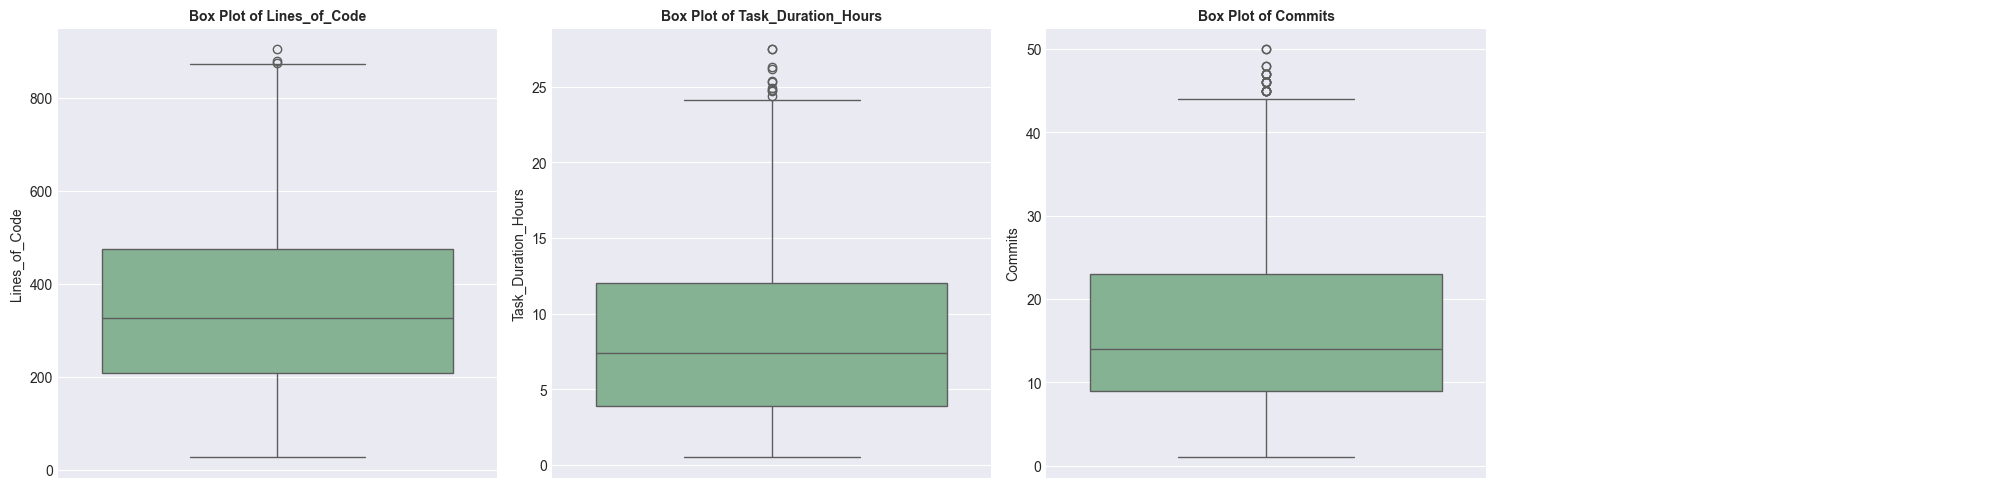

In [11]:
# Check outlier bằng IQR
cols_with_outliers = OutlierAnalyzer.get_columns_with_outliers(df)

# Vẽ boxplot cho các cột có outliers
if cols_with_outliers:
    Plotter.boxplots(df, columns=cols_with_outliers, n_cols=4)

Quan sát: `Task_Duration_Hours` và `Commits` có rất nhiều outliers (Chúng cũng là right-skewed distribution). Và dựa trên thông tin về distribution của 2 feature đều thuộc dạng right-skewed, ta nên thực hiện log transformation cho 2 features này để giảm outliers, giúp cải thiện tốc độ hội tụ các mô hình được huấn luyện sau này.

In [12]:
df = DataProcessor.log_transform(df, ['Task_Duration_Hours', 'Commits'])

Kiểm tra correlation matrix và vẽ heatmap

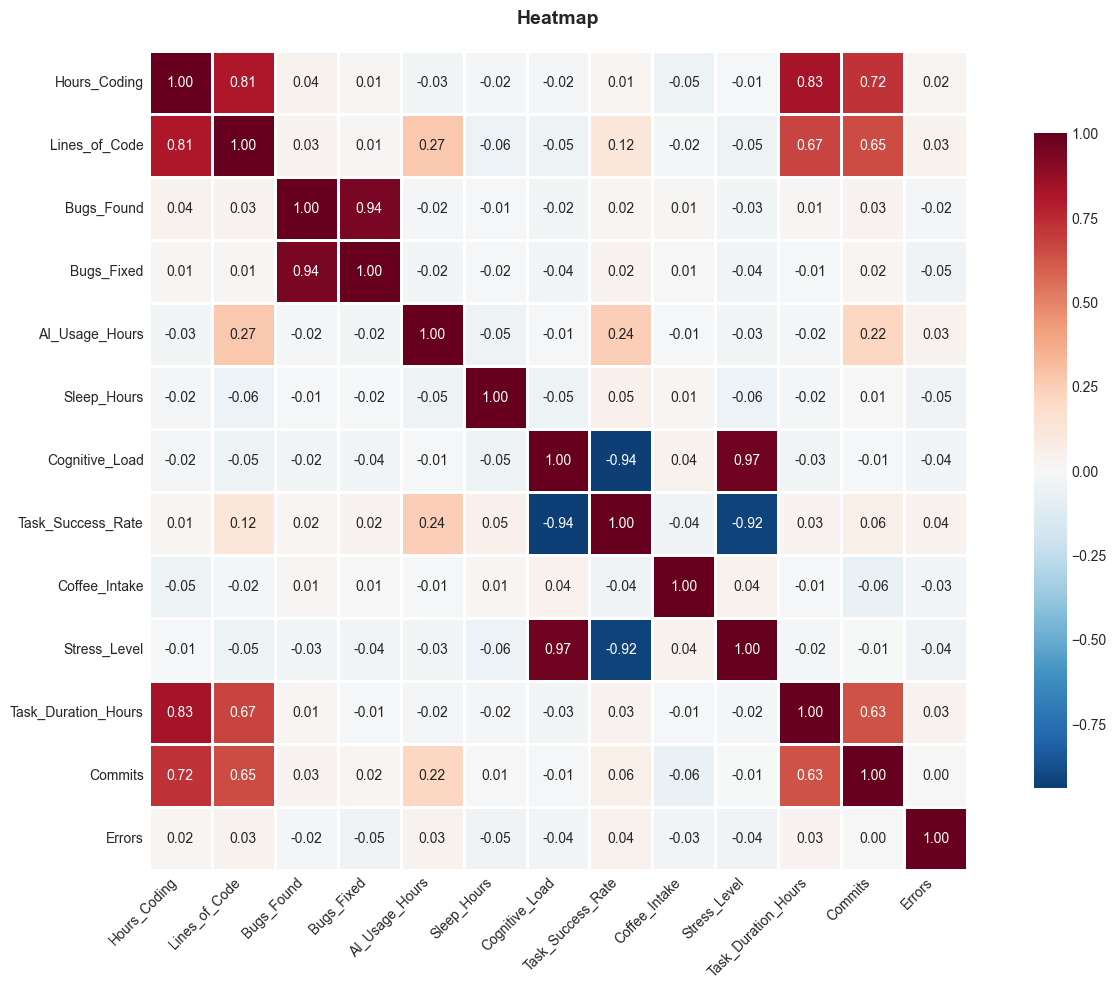

In [13]:
# Correlation matrix
correlation_matrix = CorrelationAnalyzer.get_correlation_matrix(df)

# Vẽ correlation heatmap
Plotter.heatmap(correlation_matrix, figsize=(14, 10))

Tìm kiếm các cặp đặc trưng có tương quan cao (|correlation| > 0.7)

In [14]:
high_corr = CorrelationAnalyzer.get_high_correlations(correlation_matrix, threshold=0.7)
if len(high_corr) > 0:
    display(high_corr)

,Feature 1,Feature 2,Correlation
5,Cognitive_Load,Stress_Level,0.9686
3,Bugs_Found,Bugs_Fixed,0.9419
4,Cognitive_Load,Task_Success_Rate,-0.9405
6,Task_Success_Rate,Stress_Level,-0.9201
1,Hours_Coding,Task_Duration_Hours,0.8272
0,Hours_Coding,Lines_of_Code,0.8092
2,Hours_Coding,Commits,0.7213


Quan sát:
-   `Cognitive_Load`, `Stress_Level` tương quan cực cao (0.97), gây collinearity.
-   `Bugs_Found`, `Bugs_Fixed` tương quan cực cao (0.94), gây collinearity.
-   `Stress_Level`, `Cognitive_Load` có tương quan âm mạnh với `Task_Success_Rate` (-0.92 và -0.94).
-   `Hours_Coding` tỷ lệ thuận rõ với `Lines_of_Code` (0.81), `Task_Duration_Hours` (0.79), `Commits` (0.70).
-   `Sleep_Hours`, `Coffee_Intake` có hệ số tương quan gần bằng 0 với các feature khác.

Do đó, mỗi khi xài các mô hình machine learning có tính chất tuyến tính (Như Linear Regression) hoặc các mô hình distanced-based (Như K-means clustering), chúng ta nên tránh sử dụng cùng lúc các cặp trên làm input features để giúp cho mô hình có thể học ổn định và tốt hơn.

Ngoài ra, chúng em cũng sẽ tạo thêm một số features mới để phục vụ cho các phân tích sau này.

In [15]:
# Tổng thời gian làm việc = Code tay + AI
df[config.FEATURE_TOTAL_TECH_HOURS] = df['Hours_Coding'] + df['AI_Usage_Hours']

# Cường độ dùng AI (0 đến 1)
df[config.FEATURE_AI_INTENSITY] = df['AI_Usage_Hours'] / df[config.FEATURE_TOTAL_TECH_HOURS]

# Hiệu suất: Số dòng code trên mỗi giờ làm việc
df[config.FEATURE_EFFICIENCY_LOC] = df['Lines_of_Code'] / df[config.FEATURE_TOTAL_TECH_HOURS]

# Tỷ lệ lỗi: Số bug trên mỗi 1000 dòng code
df[config.FEATURE_BUG_RATE] = (df['Bugs_Found'] / df['Lines_of_Code']) * 1000

# Chia người dùng thành 4 nhóm dựa trên mức độ dùng AI
df[config.FEATURE_AI_USER_TYPE] = pd.qcut(
    df[config.FEATURE_AI_INTENSITY],
    q=4,
    labels=config.AI_USER_TYPE_LABELS
)

# Chia lập trình viên thành 3 nhóm dựa trên lượng cà phê tiêu thụ
df[config.FEATURE_COFFEE_GROUP] = pd.cut(
    df['Coffee_Intake'],
    bins=config.COFFEE_BINS,
    labels=config.COFFEE_LABELS
)

print("Các đặc trưng mới được tạo:")
new_cols = [config.FEATURE_TOTAL_TECH_HOURS, config.FEATURE_AI_INTENSITY,
            config.FEATURE_EFFICIENCY_LOC, config.FEATURE_BUG_RATE,
            config.FEATURE_AI_USER_TYPE, config.FEATURE_COFFEE_GROUP]
for col in new_cols:
    print(f"  - {col}")

Các đặc trưng mới được tạo:
  - Total_Tech_Hours
  - AI_Intensity
  - Efficiency_LOC_per_Hour
  - Bug_Rate_per_1k_LOC
  - AI_User_Type
  - Coffee_Group


Kiểm tra các dòng dữ liệu mới

In [16]:
df.head()

,Hours_Coding,Lines_of_Code,Bugs_Found,Bugs_Fixed,AI_Usage_Hours,Sleep_Hours,Cognitive_Load,Task_Success_Rate,Coffee_Intake,Stress_Level,Task_Duration_Hours,Commits,Errors,Total_Tech_Hours,AI_Intensity,Efficiency_LOC_per_Hour,Bug_Rate_per_1k_LOC,AI_User_Type,Coffee_Group
0,7,416,9,7,6,5.9,92,34,7,99,2.442347,3.044522,3,13,0.461538,32.000000,21.634615,High AI,High (>4 cups)
1,4,269,16,13,5,5.1,85,36,2,100,2.351375,2.890372,8,9,0.555556,29.888889,59.479554,Extreme AI,Low (0-2 cups)
2,11,439,3,0,2,6.2,38,79,2,55,2.960105,3.583519,2,13,0.153846,33.769231,6.833713,Low AI,Low (0-2 cups)
3,8,472,15,9,4,4.2,26,94,5,30,2.610070,3.367296,4,12,0.333333,39.333333,31.779661,Moderate AI,High (>4 cups)
4,5,265,19,16,5,8.1,82,33,6,82,2.079442,3.258097,9,10,0.500000,26.500000,71.698113,High AI,High (>4 cups)


Ý nghĩa các đặc trưng mới:
- Tổng thời gian kỹ thuật: `Total_Tech_Hours = Hours_Coding + AI_Usage_Hours `
- Cường độ dùng AI (0 đến 1): `AI_Intensity = AI_Usage_Hours / Total_Tech_Hours`
- Hiệu suất (số dòng code trên mỗi giờ làm việc): `Efficiency_LOC_per_Hour = Lines_of_Code / Total_Tech_Hours`
- Tỷ lệ lỗi trên mỗi 1000 dòng code: `Bug_Rate_per_1k_LOC = Bugs_Found / Lines_of_Code`
- Chia lập trình viên thành 4 nhóm dựa trên mức độ dùng AI: `AI_User_Type = [Low AI, Moderate AI, High AI, Extreme AI]`
- Chia lập trình viên thành 3 nhóm dựa trên lượng cà phê tiêu thụ: `Coffee_Group = [Low (0-2 cups), Medium (3-4 cups), High (>4 cups)]`

Lưu dữ liệu mới đã xử lý

In [17]:
DataProcessor.save_data(df, config.PROCESSED_DATA_DIR)

Đã lưu dữ liệu tại: D:\Private Data\LTKHDL\AI-Developer-Productivity-Analysis\notebooks\..\dataset\processed\AI_Developer_Performance_processed.csv
